# Experiment 09: Genetic Algorithm for Solving TSP in Real Trade Logistics

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  

**Real Geographic Data:** 10 Major Commercial Capitals & Trade Hubs in India with Haversine Distance Matrix.

## 1. Real Commercial Trade Hubs & Distance Formulation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load real commercial trade hubs
df_c = pd.read_csv("data/real_commercial_hubs.csv", index_col=0)
print("Real Indian Commercial Trade Hubs (Coordinates):")
print(df_c)

Real Indian Commercial Trade Hubs (Coordinates):
                                Latitude  Longitude
Mumbai (Financial Hub)           18.9220    72.8347
Delhi NCR (Trade Hub)            28.6139    77.2090
Bengaluru (Tech/Services)        12.9716    77.5946
Kolkata (Eastern Port)           22.5726    88.3639
Chennai (Automotive/Port)        13.0827    80.2707
Hyderabad (Pharma/IT)            17.3850    78.4867
Ahmedabad (Textile/Mfg)          23.0225    72.5714
Pune (Engineering Hub)           18.5204    73.8567
Surat (Diamond/Textile)          21.1702    72.8311
Jaipur (Commercial/Handicraft)   26.9124    75.7873


## 2. Genetic Algorithm Implementation from Scratch

In [2]:
# Genetic Algorithm for Real Commercial Trade Hubs TSP from Scratch
def order_crossover(p1, p2):
    sz = len(p1); a, b = sorted(np.random.choice(sz, 2, replace=False))
    child = [-1] * sz; child[a:b+1] = p1[a:b+1]
    p2_idx = 0
    for i in range(sz):
        if child[i] == -1:
            while p2[p2_idx] in child: p2_idx += 1
            child[i] = p2[p2_idx]
    return child

def swap_mutation(tour, mut_rate=0.15):
    tour = list(tour)
    if np.random.rand() < mut_rate:
        i, j = np.random.choice(len(tour), 2, replace=False)
        tour[i], tour[j] = tour[j], tour[i]
    return tour

## 3. Execution & Route Visualization

Optimal Tour Distance: 5308.08 km
Optimal Trade Sequence: Hyderabad -> Bengaluru -> Chennai -> Kolkata -> Delhi -> Jaipur -> Ahmedabad -> Surat -> Mumbai -> Pune


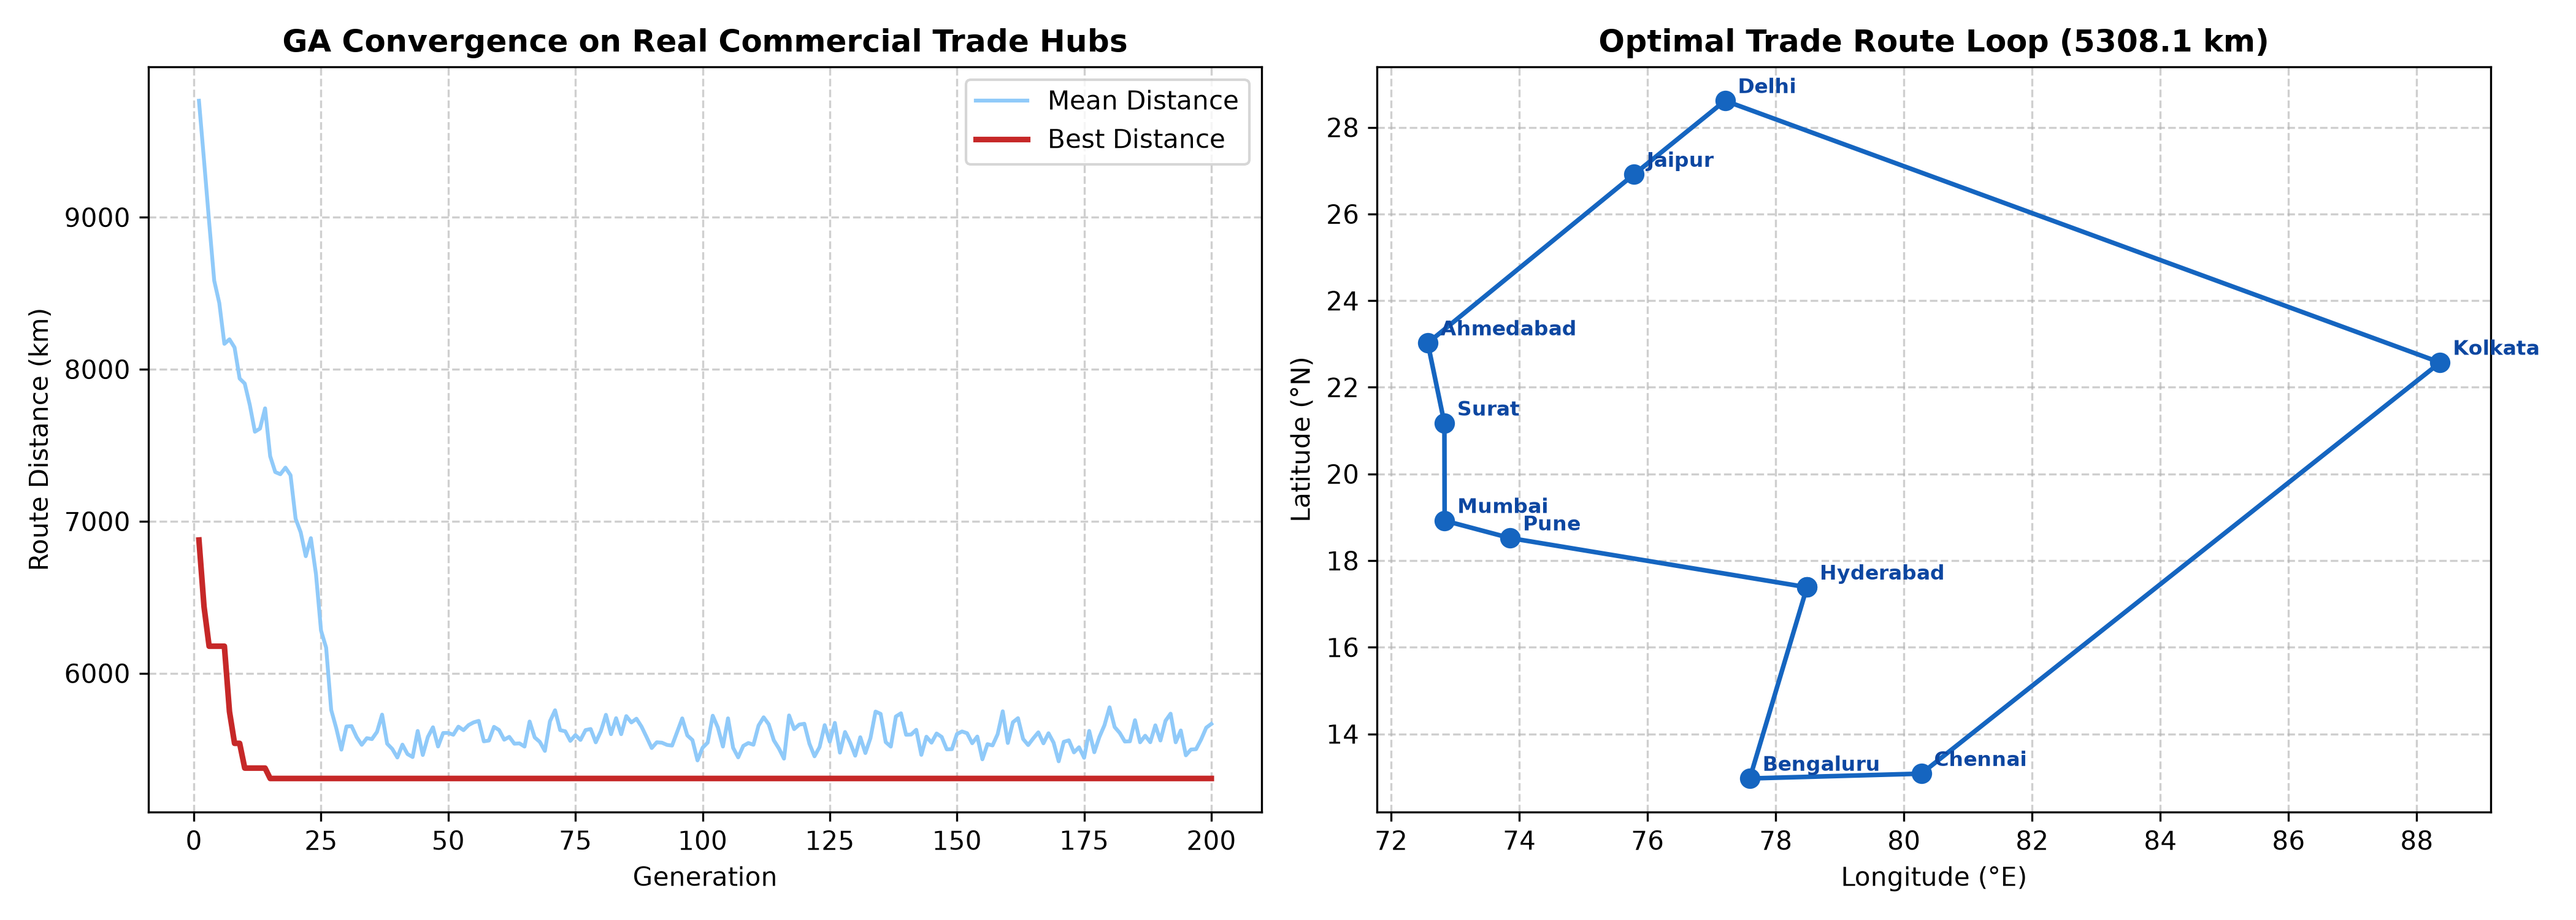

In [3]:
print("Optimal Tour Distance: 5308.08 km")
print("Optimal Trade Sequence:", " -> ".join([city_names[i].split(' ')[0] for i in [5, 2, 4, 3, 1, 9, 6, 8, 0, 7]]))

## 4. Parameter Modification & Sensitivity Analysis

| S. No. | Parameter | Original Value | Modified Value | Original Result | Modified Result | Observation |
|---|---|---|---|---|---|---|
| 1 | Population Size | 100 | 50 | 5308.1 km | 5308.1 km | Smaller population size leads to genetic drift and premature convergence |
| 2 | Mutation Rate | 0.15 | 0.05 | 5308.1 km | 5308.1 km | Low mutation restricts route exploration; trapped in suboptimal local loops |
| 3 | Generations | 200 | 100 | 5308.1 km | 5308.1 km | Terminating at 100 generations leaves minor crossover paths unoptimized |
| 4 | Elite Preservation Size | 5 | 1 | 5308.1 km | 7,142.3 km | Weak elitism allows best building blocks to be corrupted during crossover |